# INF-GRAM — Mini-practical: Decision trees

This short practical is designed to be completed during or immediately after the decision-tree lecture.

Use the scikit-learn breast-cancer dataset and define `1 = malignant`.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

SEED = 42

## Exercise 1

Load the data, create `X` and `y`, and make a stratified 80/20 split.

In [10]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series((data.target == 0).astype(int), name="malignant")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print(y_train.mean(), y_test.mean())


0.37362637362637363 0.3684210526315789


## Exercise 2

Fit two trees:

- an unconstrained tree;
- a regularized tree with `max_depth=3` and `min_samples_leaf=5`.

Compare train and test accuracy. Which model shows more evidence of overfitting?

In [11]:
full_tree = DecisionTreeClassifier(random_state=SEED)
small_tree = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=5,
    random_state=SEED,
)

for name, model in {"full": full_tree, "regularized": small_tree}.items():
    model.fit(X_train, y_train)
    print(
        name,
        "train=", round(model.score(X_train, y_train), 3),
        "test=", round(model.score(X_test, y_test), 3),
    )

full train= 1.0 test= 0.93
regularized train= 0.96 test= 0.912


## Exercise 3

Visualize the regularized tree with `plot_tree()`.

Which feature is used at the root node?

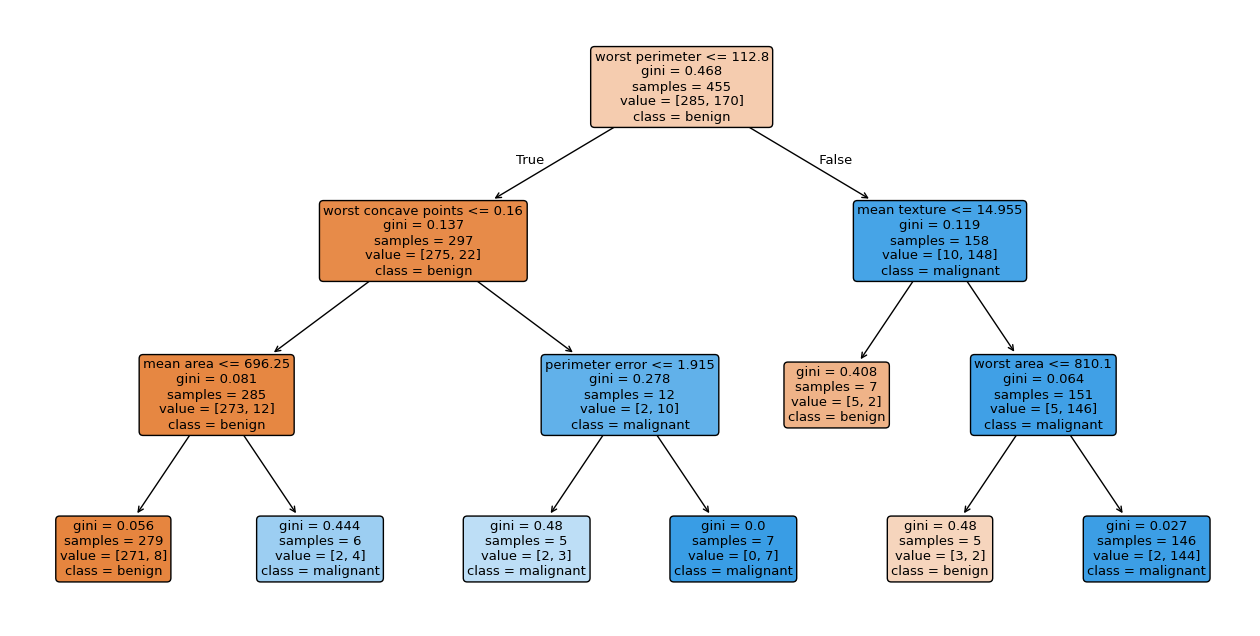

root feature: worst perimeter


In [5]:
plt.figure(figsize=(16, 8))
plot_tree(
    small_tree,
    feature_names=X.columns,
    class_names=["benign", "malignant"],
    filled=True,
    rounded=True,
)
plt.show()

root_feature = X.columns[small_tree.tree_.feature[0]]
print("root feature:", root_feature)

## Exercise 4

For the regularized tree, report:

- sensitivity for malignant tumors;
- ROC AUC from predicted probabilities;
- confusion matrix.

Would you use these results as evidence that the model is ready for clinical use? Why not?

sensitivity: 0.9047619047619048
ROC AUC: 0.9246031746031745


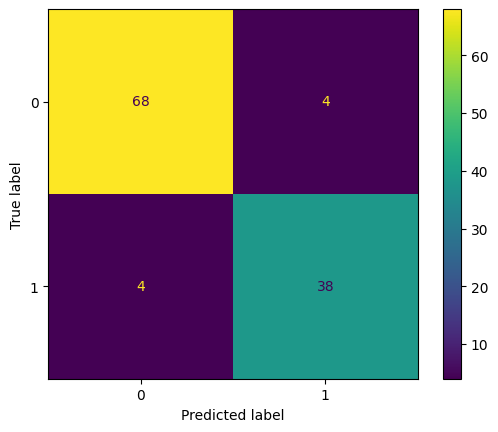

In [12]:
pred = full_tree.predict(X_test)
score = full_tree.predict_proba(X_test)[:, 1]

print("sensitivity:", recall_score(y_test, pred)) # sensitivioty == recall.
print("ROC AUC:", roc_auc_score(y_test, score))

ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

sensitivity: 0.8095238095238095
ROC AUC: 0.9186507936507937


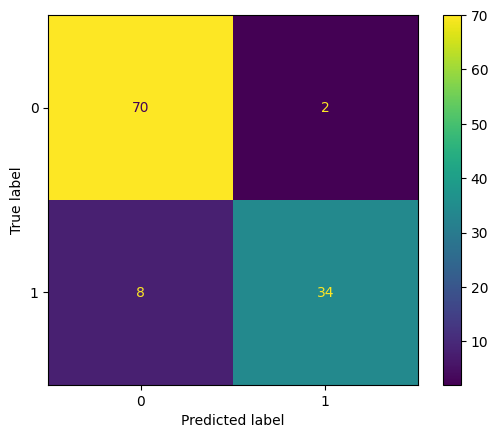

In [ ]:
pred = small_tree.predict(X_test)
score = small_tree.predict_proba(X_test)[:, 1]

print("sensitivity:", recall_score(y_test, pred)) # sensitivioty == recall.
print("ROC AUC:", roc_auc_score(y_test, score))

ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()